# Week 3, Wednesday: GridSearchCV (Hyperparameter Tuning)
Back to **supervised** learning. Dataset: **Breast Cancer** (built into scikit-learn, no upload needed). Goal: improve kNN, a Decision Tree and an SVM by searching for their best **hyperparameters**, and check honestly whether tuning helped.

## 0. Parameters vs hyperparameters
- **Parameters** are learned by the model from the data (a tree's split thresholds, a logistic regression's weights).
- **Hyperparameters** are settings *you* choose before training (`max_depth` of a tree, `n_neighbors` in kNN, `C` in an SVM). The model cannot learn them from the training step, so we **search** for good values.

In [1]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, make_scorer, ConfusionMatrixDisplay
sns.set_theme(style='whitegrid')
np.random.seed(42)

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target          # 0 = malignant, 1 = benign
# Keep a TEST SET that the search never sees. Everything we tune uses only the training part.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (426, 30)  Test: (143, 30)


In [2]:
# What does a model LEARN (parameters) vs what do WE SET (hyperparameters)?
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print('Hyperparameter I set  : max_depth =', tree.max_depth)
print('Parameters it learned : first split is on feature', data.feature_names[tree.tree_.feature[0]],
      'at threshold', round(tree.tree_.threshold[0], 3))

Hyperparameter I set  : max_depth = 3
Parameters it learned : first split is on feature worst radius at threshold 16.795


## 1. Baselines: default settings, scored by cross-validation on the training set and once on the test set

In [3]:
models = {
    'kNN':           Pipeline([('scale', StandardScaler()), ('model', KNeighborsClassifier())]),
    'Decision Tree': Pipeline([('scale', StandardScaler()), ('model', DecisionTreeClassifier(random_state=42))]),
    'SVM':           Pipeline([('scale', StandardScaler()), ('model', SVC(random_state=42))]),
}
baseline = {}
for name, pipe in models.items():
    s = cross_val_score(pipe, X_train, y_train, cv=cv)
    baseline[name] = dict(cv_mean=s.mean(), cv_std=s.std(), test=pipe.fit(X_train, y_train).score(X_test, y_test))
base = pd.DataFrame(baseline).T.round(3); base

,cv_mean,cv_std,test
kNN,0.967,0.014,0.979
Decision Tree,0.925,0.016,0.923
SVM,0.967,0.005,0.979


The scaler is **inside the Pipeline**, so during cross-validation it is refit on each training fold only (no leakage), and the search can tune the scaler's pipeline as one unit.

## 2. GridSearchCV on kNN
GridSearchCV tries **every combination** in the grid. For each combination it runs k-fold cross-validation, then picks the combination with the best mean CV score and (by default) **refits** it on the whole training set.

Number of model fits = (number of combinations) x (number of folds). Parameter names inside a pipeline use `stepname__parameter`.

In [4]:
knn_grid = {'model__n_neighbors': list(range(1, 31)),
            'model__weights': ['uniform', 'distance'],
            'model__metric': ['euclidean', 'manhattan']}
n_combos = np.prod([len(v) for v in knn_grid.values()])
print(f'{n_combos} combinations x 5 folds = {n_combos * 5} model fits')

t0 = time.time()
gs_knn = GridSearchCV(models['kNN'], knn_grid, cv=cv, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
t_knn = time.time() - t0
print(f'Search took {t_knn:.1f} s')
print('Best parameters :', gs_knn.best_params_)
print('best_score_ (mean CV accuracy on TRAIN folds):', round(gs_knn.best_score_, 4))
print('Test accuracy of the tuned model          :', round(gs_knn.score(X_test, y_test), 4),
      '  (default kNN test accuracy was', base.loc['kNN', 'test'], ')')

120 combinations x 5 folds = 600 model fits
Search took 10.2 s
Best parameters : {'model__metric': 'euclidean', 'model__n_neighbors': 10, 'model__weights': 'uniform'}
best_score_ (mean CV accuracy on TRAIN folds): 0.9718
Test accuracy of the tuned model          : 0.965   (default kNN test accuracy was 0.979 )


In [5]:
res = pd.DataFrame(gs_knn.cv_results_)
cols = ['param_model__n_neighbors', 'param_model__weights', 'param_model__metric', 'mean_test_score', 'std_test_score', 'rank_test_score']
res.sort_values('rank_test_score')[cols].head(10).round(4).reset_index(drop=True)

,param_model__n_neighbors,param_model__weights,param_model__metric,mean_test_score,std_test_score,rank_test_score
0,14,distance,euclidean,0.9718,0.0058,1
1,10,uniform,euclidean,0.9718,0.0058,1
2,12,distance,manhattan,0.9718,0.0058,1
3,12,uniform,manhattan,0.9718,0.0120,1
4,9,uniform,euclidean,0.9695,0.0094,5
5,10,distance,euclidean,0.9695,0.0094,5
6,8,distance,euclidean,0.9695,0.0094,5
7,9,distance,euclidean,0.9695,0.0094,5
8,13,distance,euclidean,0.9695,0.0058,9
9,13,uniform,euclidean,0.9695,0.0058,9


`cv_results_` holds the score of **every** combination. `mean_test_score` is the mean CV accuracy, `std_test_score` is the spread over the 5 folds, and `rank_test_score` ranks them (1 = best). Note: here "test" in those names means the **validation fold**, not your held-out test set.

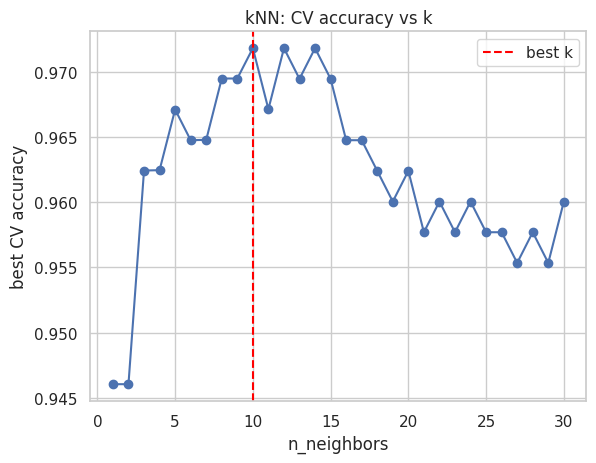

In [6]:
# How does the score change with k? (best value of the other settings for each k)
by_k = res.groupby('param_model__n_neighbors')['mean_test_score'].max()
plt.plot(by_k.index, by_k.values, 'o-'); plt.axvline(gs_knn.best_params_['model__n_neighbors'], color='red', ls='--', label='best k')
plt.xlabel('n_neighbors'); plt.ylabel('best CV accuracy'); plt.title('kNN: CV accuracy vs k'); plt.legend(); plt.show()

## 3. GridSearchCV on a Decision Tree

In [7]:
tree_grid = {'model__max_depth': [1, 2, 3, 4, 5, 6, 8, 10, None],
             'model__min_samples_leaf': [1, 2, 5, 10, 20],
             'model__criterion': ['gini', 'entropy']}
n_combos = np.prod([len(v) for v in tree_grid.values()]); print(f'{n_combos} combinations x 5 folds = {n_combos * 5} fits')
t0 = time.time()
gs_tree = GridSearchCV(models['Decision Tree'], tree_grid, cv=cv, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
t_tree = time.time() - t0
print(f'Search took {t_tree:.1f} s | best params:', gs_tree.best_params_)
print('best_score_:', round(gs_tree.best_score_, 4), '| test accuracy:', round(gs_tree.score(X_test, y_test), 4),
      '| default tree test accuracy:', base.loc['Decision Tree', 'test'])

90 combinations x 5 folds = 450 fits
Search took 6.5 s | best params: {'model__criterion': 'gini', 'model__max_depth': 6, 'model__min_samples_leaf': 2}
best_score_: 0.9413 | test accuracy: 0.8951 | default tree test accuracy: 0.923


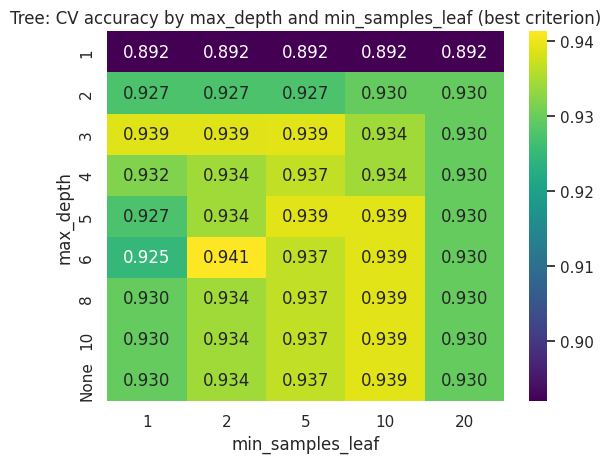

In [8]:
res_t = pd.DataFrame(gs_tree.cv_results_)
res_t['depth'] = res_t['param_model__max_depth'].astype(str)
heat = res_t.pivot_table(index='depth', columns='param_model__min_samples_leaf', values='mean_test_score', aggfunc='max')
heat = heat.reindex([str(d) for d in [1, 2, 3, 4, 5, 6, 8, 10, None]])
sns.heatmap(heat, annot=True, fmt='.3f', cmap='viridis'); plt.title('Tree: CV accuracy by max_depth and min_samples_leaf (best criterion)')
plt.xlabel('min_samples_leaf'); plt.ylabel('max_depth'); plt.show()

## 4. GridSearchCV on an SVM
An SVM has two key hyperparameters: **C** (how strictly it avoids misclassifying training points; large C = stricter, risk of overfitting) and **gamma** (how far one training point's influence reaches in the RBF kernel).

In [9]:
svm_grid = {'model__C': [0.1, 1, 10, 100],
            'model__gamma': ['scale', 0.001, 0.01, 0.1],
            'model__kernel': ['rbf', 'linear']}
n_combos = np.prod([len(v) for v in svm_grid.values()]); print(f'{n_combos} combinations x 5 folds = {n_combos * 5} fits')
t0 = time.time()
gs_svm = GridSearchCV(models['SVM'], svm_grid, cv=cv, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
t_svm = time.time() - t0
print(f'Search took {t_svm:.1f} s | best params:', gs_svm.best_params_)
print('best_score_:', round(gs_svm.best_score_, 4), '| test accuracy:', round(gs_svm.score(X_test, y_test), 4),
      '| default SVM test accuracy:', base.loc['SVM', 'test'])

32 combinations x 5 folds = 160 fits
Search took 3.7 s | best params: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
best_score_: 0.9766 | test accuracy: 0.986 | default SVM test accuracy: 0.979


## 5. The honest comparison table
Four numbers per model: **default CV**, **tuned CV** (`best_score_`), **default test**, **tuned test**.
- `best_score_` is slightly **optimistic**, because we picked the winner out of many tries on those same folds.
- The **test score** is the honest one: the search never saw those rows.

In [10]:
tuned = {'kNN': gs_knn, 'Decision Tree': gs_tree, 'SVM': gs_svm}
times = {'kNN': t_knn, 'Decision Tree': t_tree, 'SVM': t_svm}
summary = pd.DataFrame({
    'default CV': base['cv_mean'], 'tuned CV (best_score_)': {k: v.best_score_ for k, v in tuned.items()},
    'default test': base['test'], 'tuned test': {k: v.score(X_test, y_test) for k, v in tuned.items()},
    'CV std (default)': base['cv_std'], 'search time (s)': times,
}).round(3)
summary['test gain'] = (summary['tuned test'] - summary['default test']).round(3)
display(summary)
for k, v in tuned.items(): print(f'{k:14s} best params: {v.best_params_}')

,default CV,tuned CV (best_score_),default test,tuned test,CV std (default),search time (s),test gain
kNN,0.967,0.972,0.979,0.965,0.014,10.236,-0.014
Decision Tree,0.925,0.941,0.923,0.895,0.016,6.528,-0.028
SVM,0.967,0.977,0.979,0.986,0.005,3.681,0.007


kNN            best params: {'model__metric': 'euclidean', 'model__n_neighbors': 10, 'model__weights': 'uniform'}
Decision Tree  best params: {'model__criterion': 'gini', 'model__max_depth': 6, 'model__min_samples_leaf': 2}
SVM            best params: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}


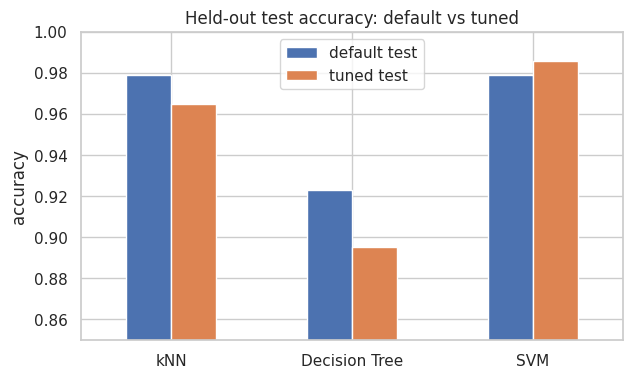

In [11]:
summary[['default test', 'tuned test']].plot.bar(figsize=(7, 4), ylim=(0.85, 1.0), title='Held-out test accuracy: default vs tuned'); plt.ylabel('accuracy'); plt.xticks(rotation=0); plt.show()

**Reading the table honestly.** The test set has only **143** rows, so one extra correct prediction changes the accuracy by about **0.007**. A "gain" of 0.007 or 0.014 is one or two patients, not proof. Compare any gain with the fold-to-fold spread (`CV std`, about 0.01-0.03). Tuning often gives small gains on easy datasets like this one, and it can occasionally even look *worse* on the test set by chance.

## 6. Tune for what matters: recall on malignant
For cancer, the costliest mistake is a **missed malignant tumour** (false negative for class 0). Accuracy doesn't reflect that, so we can ask the search to optimise **recall of the malignant class** instead.

In [12]:
recall_malignant = make_scorer(recall_score, pos_label=0)
gs_rec = GridSearchCV(models['kNN'], knn_grid, cv=cv, scoring=recall_malignant, n_jobs=-1).fit(X_train, y_train)
print('Best params for malignant recall:', gs_rec.best_params_)
print('CV malignant recall:', round(gs_rec.best_score_, 3))
for name, m in [('kNN default', models['kNN'].fit(X_train, y_train)), ('kNN tuned for accuracy', gs_knn.best_estimator_), ('kNN tuned for recall', gs_rec.best_estimator_)]:
    p = m.predict(X_test)
    print(f'{name:24s} test accuracy = {accuracy_score(y_test, p):.3f}  malignant recall = {recall_score(y_test, p, pos_label=0):.3f}  missed malignant = {int(((y_test == 0) & (p == 1)).sum())}')

Best params for malignant recall: {'model__metric': 'euclidean', 'model__n_neighbors': 2, 'model__weights': 'uniform'}
CV malignant recall: 0.944
kNN default              test accuracy = 0.979  malignant recall = 0.943  missed malignant = 3
kNN tuned for accuracy   test accuracy = 0.965  malignant recall = 0.925  missed malignant = 4
kNN tuned for recall     test accuracy = 0.937  malignant recall = 0.962  missed malignant = 2


The `scoring` argument decides **what "best" means**. Tuning for accuracy and tuning for recall can pick different settings, so choose the metric that matches the real-world cost of mistakes.
